<a href="https://colab.research.google.com/github/johanndeboda/customer-service-chatbot/blob/main/customer_service_chatbot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Service Chatbot — Multi-Agent with LangGraph + Gemini

A customer service assistant for a laptop store. A **Router** reads each message and sends it to one of three specialist agents:

| Agent | Handles | Tools |
|---|---|---|
| Product Agent | Features, specs, pricing, recommendations | `list_laptops`, `get_product_features`, `get_laptop_price` |
| Orders Agent | Order status, delivery dates, quantity changes | `get_order_details`, `update_quantity` |
| Refund Agent | Refund/return policy, refund eligibility | `get_refund_policy`, `check_refund_eligibility` |

Greetings and goodbyes go to a small Small Talk node.

**Memory:** the whole router graph is compiled with LangGraph `MemorySaver`. Every turn is saved under a `thread_id`, so follow-up questions like *"how much does it cost?"* or *"can I return it?"* use earlier turns.

**Model:** Google Gemini (`gemini-3.1-flash-lite`) via `langchain-google-genai`. The API key is loaded from a Colab secret — never hard-coded.

Based on the starter code in [build-ai-agents-and-chatbots-with-langgraph](https://github.com/myrah/build-ai-agents-and-chatbots-with-langgraph-2021112), notebooks 03, 04 and 06, rewritten to use Gemini, a third agent, and graph-level memory.

## 1. Setup — packages and data

In [16]:
# Install the libraries we need (Colab already has pandas)
!pip install -q langchain-google-genai langgraph langchain-core pypdf

# Get the data files (laptop orders, pricing, product descriptions) from the repo.
# Skips the clone if the data folder is already here (e.g. running locally).
import os
if not os.path.exists("data"):
    !git clone -q https://github.com/johanndeboda/customer-service-chatbot.git
    %cd customer-service-chatbot
print("Data files:", os.listdir("data"))

Data files: ['Laptop Orders.csv', 'Laptop product descriptions.pdf', 'EcoSprint_Specification_Document.pdf', 'Laptop pricing.csv', 'README.md']


## 2. Load the API key and set up the model

In [17]:
import os
from langchain_google_genai import ChatGoogleGenerativeAI

# Load the Gemini API key from Colab secrets (key icon in the left sidebar).
# The secret is named "main_gemini_key". Nothing is hard-coded in this notebook.
try:
    from google.colab import userdata
    os.environ["GOOGLE_API_KEY"] = userdata.get("main_gemini_key")
except ImportError:
    # Running outside Colab: load from a .env file instead (see README)
    from dotenv import load_dotenv
    load_dotenv()

if not os.getenv("GOOGLE_API_KEY"):
    raise RuntimeError("Missing GOOGLE_API_KEY. Add the Colab secret or a .env file.")

# One shared LLM for the router and all agents.
# temperature=0 keeps routing decisions consistent between runs.
model = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite", temperature=0)

print(model.invoke("Reply with: model ready").text)

model ready


## 3. Load the store data

In [18]:
import pandas as pd
from pypdf import PdfReader

# Orders and pricing come from CSV files
orders_df = pd.read_csv("data/Laptop Orders.csv")
pricing_df = pd.read_csv("data/Laptop pricing.csv")

# Product descriptions come from a PDF.
# Each laptop has a title line followed by its description, so we split
# the text into a {laptop name: description} dictionary.
pdf_text = "\n".join(page.extract_text() for page in PdfReader("data/Laptop product descriptions.pdf").pages)
laptop_names = pricing_df["Name"].tolist()

product_descriptions = {}
for i, name in enumerate(laptop_names):
    start = pdf_text.find(name)
    end = pdf_text.find(laptop_names[i + 1]) if i + 1 < len(laptop_names) else len(pdf_text)
    product_descriptions[name] = " ".join(pdf_text[start + len(name):end].split())

display(orders_df)
display(pricing_df)

,Order ID,Product Ordered,Quantity Ordered,Delivery Date
0,ORD-8276,SpectraBook S,3,2024-10-16
1,ORD-6948,OmegaPro G17,3,2024-10-25
2,ORD-7311,NanoEdge Flex,2,2024-10-19
3,ORD-4633,OmegaPro G17,2,2024-10-15
4,ORD-2050,GammaAir X,2,2024-10-26


,Name,Price,ShippingDays
0,AlphaBook Pro,1499,2
1,GammaAir X,1399,7
2,SpectraBook S,2499,7
3,OmegaPro G17,2199,14
4,NanoEdge Flex,1699,2


## 4. Tools
Tools are plain Python functions the agents can call. The docstring tells the LLM what each tool does.

In [19]:
from langchain_core.tools import tool

def find_laptop(laptop_name: str):
    """Helper: match a partial name like 'spectra' to 'SpectraBook S'."""
    for name in laptop_names:
        if laptop_name.lower() in name.lower() or name.lower() in laptop_name.lower():
            return name
    return None

# ---------- Product tools ----------
@tool
def list_laptops() -> str:
    """Returns every laptop the store sells with its features. Use this before recommending a laptop."""
    return "\n".join(
    f"{row['Name']} (${row['Price']}, ships in {row['ShippingDays']} days): {product_descriptions[row['Name']]}"
    for _, row in pricing_df.iterrows()
    )

@tool
def get_product_features(laptop_name: str) -> str:
    """Returns the features and specs (CPU, memory, storage, use case) of a laptop, given its name."""
    name = find_laptop(laptop_name)
    if not name:
        return f"No laptop named '{laptop_name}'. Available: {', '.join(laptop_names)}"
    return f"{name}: {product_descriptions[name]}"

@tool
def get_laptop_price(laptop_name: str) -> str:
    """Returns the price and shipping time of a laptop, given its name."""
    name = find_laptop(laptop_name)
    if not name:
        return f"No laptop named '{laptop_name}'."
    row = pricing_df[pricing_df["Name"] == name].iloc[0]
    return f"{name} costs ${row['Price']} and ships in {row['ShippingDays']} days."

# ---------- Order tools ----------
@tool
def get_order_details(order_id: str) -> str:
    """Returns the laptop ordered, quantity and delivery date for an order ID like ORD-7311."""
    match = orders_df[orders_df["Order ID"] == order_id.strip().upper()]
    if match.empty:
        return f"No order found with ID {order_id}."
    return str(match.iloc[0].to_dict())

@tool
def update_quantity(order_id: str, new_quantity: int) -> str:
    """Updates the quantity of laptops on an order. Use the NEW total quantity, not the change."""
    order_id = order_id.strip().upper()
    if orders_df[orders_df["Order ID"] == order_id].empty:
        return f"No order found with ID {order_id}."
    orders_df.loc[orders_df["Order ID"] == order_id, "Quantity Ordered"] = new_quantity
    return f"Order {order_id} updated to quantity {new_quantity}."

# ---------- Refund tools ----------
# The store's refund policy (written for this project)
REFUND_POLICY = """
- Laptops can be returned within 14 days of delivery for a full refund.
- The laptop must include all original accessories and packaging.
- Opened laptops have a 10% restocking fee unless they are defective.
- Defective laptops can be returned for a full refund or replacement within 30 days.
- Refunds go back to the original payment method within 5-7 business days.
- Shipping costs are not refunded unless the laptop is defective.
"""

# The sample orders are from Oct 2024, so we simulate "today" as Nov 1, 2024.
# This makes some orders eligible for a refund and some not, which is good for the demo.
TODAY = pd.Timestamp("2024-11-01")
RETURN_WINDOW_DAYS = 14

@tool
def get_refund_policy() -> str:
    """Returns the store's refund and return policy."""
    return REFUND_POLICY

@tool
def check_refund_eligibility(order_id: str) -> str:
    """Checks whether an order is still inside the 14-day return window, given its order ID."""
    match = orders_df[orders_df["Order ID"] == order_id.strip().upper()]
    if match.empty:
        return f"No order found with ID {order_id}."
    order = match.iloc[0]
    days = (TODAY - pd.Timestamp(order["Delivery Date"])).days
    if days <= RETURN_WINDOW_DAYS:
        return f"Order {order['Order ID']} ({order['Product Ordered']}) was delivered {days} days ago. ELIGIBLE: {RETURN_WINDOW_DAYS - days} days left to return."
    return f"Order {order['Order ID']} ({order['Product Ordered']}) was delivered {days} days ago. NOT eligible: the {RETURN_WINDOW_DAYS}-day window has passed (defective items still have 30 days)."

# Quick tool test (no LLM involved)
print(get_product_features.invoke({"laptop_name": "spectra"}))
print(check_refund_eligibility.invoke({"order_id": "ORD-7311"}))

SpectraBook S: Designed for power users, SpectraBook S features an Intel Core i9 processor, 64GB RAM, and a massive 2TB SSD. This workstation-class laptop is perfect for intensive tasks like video editing and 3D rendering.
Order ORD-7311 (NanoEdge Flex) was delivered 13 days ago. ELIGIBLE: 1 days left to return.


## 5. The three specialist agents

Each agent is a ReAct agent (`create_react_agent`): the LLM decides which tool to call, reads the result, and repeats until it can answer. Each one has its own **system prompt** that defines its role and keeps it to its own tools.

In [20]:
from langgraph.prebuilt import create_react_agent

# Shared role for every agent: a customer service / sales assistant for the store
COMPANY_ROLE = """You are a friendly, professional customer service and sales assistant for TechNest,
an online laptop store. Keep answers short and clear. Only use facts from your tools, never make up
products, prices, orders, or policies. Use the earlier conversation to understand follow-up questions
(for example, "it" or "that laptop" means the laptop or order discussed earlier)."""

product_agent = create_react_agent(
    model,
    tools=[list_laptops, get_product_features, get_laptop_price],
    prompt=COMPANY_ROLE + """
Your job: answer product questions and recommend laptops. When recommending, ask about or use the
customer's needs (budget, gaming, portability, creative work), then suggest 1-2 laptops with a reason and price.""",
    name="Product_Agent",
)

orders_agent = create_react_agent(
    model,
    tools=[get_order_details, update_quantity],
    prompt=COMPANY_ROLE + """
Your job: look up order status and delivery dates, and update order quantities.
Only share details of the order the customer asked about. Confirm changes after you make them.""",
    name="Orders_Agent",
)

refund_agent = create_react_agent(
    model,
    tools=[get_refund_policy, check_refund_eligibility, get_order_details],
    prompt=COMPANY_ROLE + """
Your job: explain the refund and return policy and check if an order can still be refunded.
If the customer mentions an order, check its eligibility. Explain any restocking fee that applies.
You cannot start returns yourself. If they want to return, tell them to email returns@technest.com with their order ID.""",
    name="Refund_Agent",
)

/tmp/ipykernel_4401/2681376249.py:9: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  product_agent = create_react_agent(
/tmp/ipykernel_4401/2681376249.py:18: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  orders_agent = create_react_agent(
/tmp/ipykernel_4401/2681376249.py:27: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  refund_agent = create_react_agent(


## 6. Router + graph + memory

The **Router** node asks the LLM to classify the latest message (using recent history for context) into one route. A conditional edge then sends the conversation to the matching agent.

**Memory:** the graph is compiled with `MemorySaver()`. After each turn LangGraph saves the full message list under the conversation's `thread_id`. On the next turn it loads that history first, so every agent sees what was said before.

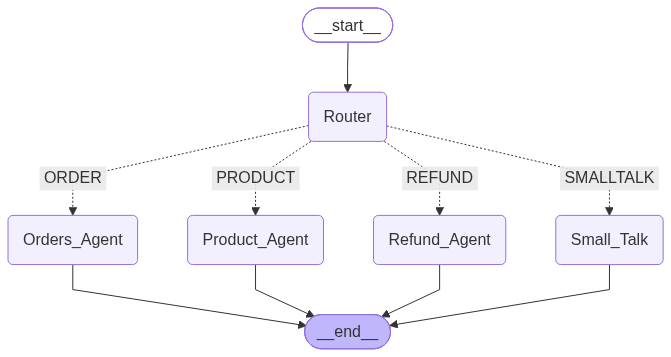

In [21]:
from typing import Annotated, Literal, TypedDict
from pydantic import BaseModel, Field
from langchain_core.messages import AIMessage, AnyMessage, HumanMessage, SystemMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver

# ---------- State: what the graph remembers ----------
class ChatState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]  # add_messages appends new messages to history
    route: str                                           # which agent the router picked this turn

# ---------- Router ----------
class Route(BaseModel):
    """The router's decision. Structured output forces the LLM to pick exactly one option."""
    route: Literal["PRODUCT", "ORDER", "REFUND", "SMALLTALK"] = Field(description="Where to send the message")

ROUTER_PROMPT = """You route customer messages for a laptop store. Pick ONE route for the LATEST message:
PRODUCT: laptop features, specs, prices, comparisons, or recommendations.
ORDER: order status, order details, delivery dates, or changing an order quantity.
REFUND: refunds, returns, return windows, restocking fees, or whether an order can be returned.
SMALLTALK: greetings, thanks, goodbyes, or anything unrelated to the store.
Use the earlier messages to resolve follow-ups like "how much is it?" or "can I return it?"."""

router_llm = model.with_structured_output(Route)

def router_node(state: ChatState):
    # Last 6 messages are enough context to classify follow-up questions
    recent = state["messages"][-6:]
    decision = router_llm.invoke([SystemMessage(ROUTER_PROMPT)] + recent)
    print(f"   [Router -> {decision.route}]")
    return {"route": decision.route}

def pick_agent(state: ChatState):
    # Conditional edge: read the router's decision and return the next node's name
    return state["route"]

# ---------- Agent nodes ----------
def make_agent_node(agent, name):
    """Wraps a specialist agent as a graph node. It gets the full conversation history
    and returns only its final answer, so tool-call steps don't clutter the chat history."""
    def node(state: ChatState):
        result = agent.invoke({"messages": state["messages"]})
        return {"messages": [AIMessage(content=result["messages"][-1].text, name=name)]}
    return node

def smalltalk_node(state: ChatState):
    prompt = COMPANY_ROLE + """ Reply briefly to greetings, thanks, or goodbyes. Mention you can help with
laptop recommendations, order status, and refunds. Politely steer unrelated questions back to the store."""
    reply = model.invoke([SystemMessage(prompt)] + state["messages"])
    return {"messages": [AIMessage(content=reply.text, name="Small_Talk")]}

# ---------- Build the graph ----------
graph = StateGraph(ChatState)
graph.add_node("Router", router_node)
graph.add_node("Product_Agent", make_agent_node(product_agent, "Product_Agent"))
graph.add_node("Orders_Agent", make_agent_node(orders_agent, "Orders_Agent"))
graph.add_node("Refund_Agent", make_agent_node(refund_agent, "Refund_Agent"))
graph.add_node("Small_Talk", smalltalk_node)

graph.add_edge(START, "Router")
graph.add_conditional_edges("Router", pick_agent, {
    "PRODUCT": "Product_Agent",
    "ORDER": "Orders_Agent",
    "REFUND": "Refund_Agent",
    "SMALLTALK": "Small_Talk",
})
for node in ["Product_Agent", "Orders_Agent", "Refund_Agent", "Small_Talk"]:
    graph.add_edge(node, END)  # each agent answers, then the turn ends

# MemorySaver = conversation memory across turns (keyed by thread_id)
chatbot = graph.compile(checkpointer=MemorySaver())

# Show the architecture diagram
from IPython.display import Image, display
try:
    display(Image(chatbot.get_graph().draw_mermaid_png()))
except Exception:
    print(chatbot.get_graph().draw_mermaid())  # fallback if the image service is unavailable

## 7. Chat helper

In [22]:
import uuid

def new_conversation():
    """Each conversation gets its own thread_id. Same thread_id = same memory."""
    return {"configurable": {"thread_id": str(uuid.uuid4())}}

def chat(message, config):
    """Send one user message and print the reply. Only the NEW message is sent;
    MemorySaver supplies the earlier turns automatically."""
    print(f"USER  : {message}")
    result = chatbot.invoke({"messages": [HumanMessage(message)]}, config)
    reply = result["messages"][-1]
    print(f"{reply.name}: {reply.content}\n" + "-" * 70)

## 8. Demo — one conversation hitting all three agents

Turns 3, 5, 6 and 8 only make sense with memory: *"it"*, *"that laptop"*, *"my order"* refer to earlier turns.

In [23]:
config = new_conversation()

demo = [
    "Hi there!",                                                     # Small talk
    "I need a laptop for video editing. What do you recommend?",     # Product: suggestion
    "How much does it cost and how fast does it ship?",              # Product: follow-up (memory)
    "Also, what's the status of my order ORD-7311?",                 # Orders
    "Can you add one more of that laptop to the order?",             # Orders: follow-up (memory)
    "Actually, can I return that order instead?",                    # Refund: uses order from memory
    "What about order ORD-8276? Can I get a refund?",                # Refund: not eligible
    "Would there be a fee if I already opened the laptop from my first order?",  # Refund: memory
    "Thanks, bye!",                                                  # Small talk
]

for msg in demo:
    chat(msg, config)

USER  : Hi there!
   [Router -> SMALLTALK]
Small_Talk: Hello! Welcome to TechNest. I'm here to help you with laptop recommendations, checking your order status, or processing refunds. How can I assist you today?
----------------------------------------------------------------------
USER  : I need a laptop for video editing. What do you recommend?
   [Router -> PRODUCT]
Product_Agent: For video editing, I recommend the **SpectraBook S** or the **NanoEdge Flex**.

*   **SpectraBook S ($2,499):** This is a workstation-class laptop with an Intel Core i9 processor, 64GB of RAM, and a 2TB SSD, making it ideal for intensive editing tasks.
*   **NanoEdge Flex ($1,799):** This 2-in-1 features the M1 Pro chip and 16GB of memory, offering great performance and versatility for creative professionals.

Do either of these sound like a good fit for your needs?
----------------------------------------------------------------------
USER  : How much does it cost and how fast does it ship?
   [Router -> 

## 9. Memory check — two separate customers

Two `thread_id`s = two separate memories. Both ask *"What's its price?"* and each gets the answer for their own laptop.

In [24]:
customer_1 = new_conversation()
customer_2 = new_conversation()

chat("Tell me about the OmegaPro G17", customer_1)
chat("Tell me about the NanoEdge Flex", customer_2)
chat("What's its price?", customer_1)   # should answer OmegaPro G17
chat("What's its price?", customer_2)   # should answer NanoEdge Flex

# Show what MemorySaver stored for customer 1
saved = chatbot.get_state(customer_1).values["messages"]
print(f"\nMemorySaver holds {len(saved)} messages for customer 1:")
for m in saved:
    print(f"  {m.type:>5}: {m.content[:70]}")

USER  : Tell me about the OmegaPro G17
   [Router -> PRODUCT]
Product_Agent: The OmegaPro G17 is a gaming powerhouse equipped with a Ryzen 9 5900HX CPU, 32GB of RAM, and a 1TB SSD. It features a 17-inch high-refresh-rate display and a powerful graphics card, making it ideal for high-end gaming.

It is priced at $2,199 and ships in 14 days. Would you like to know about any other laptops, or are you looking for something specific for your gaming needs?
----------------------------------------------------------------------
USER  : Tell me about the NanoEdge Flex
   [Router -> PRODUCT]
Product_Agent: The NanoEdge Flex is a versatile 2-in-1 laptop featuring an Apple M1 Pro chip, 16GB of unified memory, and a 512GB SSD. It is designed for creative professionals who need a device that can easily switch between laptop and tablet modes.

It is priced at $1,699 and typically ships in 2 days. Would you like to know anything else about it?
----------------------------------------------------------

## 10. Try it yourself (optional)
Type messages to chat live. Type `quit` to stop.

In [ ]:
config = new_conversation()
while True:
    msg = input("You: ")
    if msg.strip().lower() in ("quit", "exit", "bye"):
        break
    chat(msg, config)